In [1]:
import numpy as np
from numpy.fft import fft
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import metas_unclib as metas
from scipy import special
from scipy import stats


metas.use_mcprop(1000) 

# Funciones de ayuda

### Plots

In [2]:
def plot_f(f,marker="-o", linewidth = 1.0, markersize=5.0, ax=None):
    '''
    Helper function to plot spectrums
    '''
    espec=20*np.log10(np.abs(f)/len(f))
    espec=np.fft.fftshift(espec)
    
    espec=espec[len(f)//2:]
    if ax==None:
        ax=plt.gca()
    ax.plot(espec, marker,linewidth=linewidth, markersize=markersize)
    ax.set_ylim(np.max(espec)-75,np.max(espec)+5)

def plot_p(f,marker="-o", linewidth = 1.0, markersize=5.0, ax=None, clear_prop = 0.05):
    '''
    Helper function to plot phase spectrums
    '''
    signal_invalid = np.argwhere(np.abs(f)<clear_prop*np.max(np.abs(f)))
    espec = np.angle(f)
    espec[signal_invalid] = 0
    espec=np.fft.fftshift(espec)
    
    espec=espec[len(f)//2:]
    if ax==None:
        ax=plt.gca()
    ax.plot(espec, marker,linewidth=linewidth, markersize=markersize)
    

### Incertidumbre de Magnitud Aproximada

In [3]:

def get_chi_squared_variance(variable_mean, variable_std):
    '''
    Helper function to calculate non-centered chi-squared variance
    '''
    return 2*(variable_std**4) + 4*(variable_std**2)*(variable_mean**2)

def get_approx_variance_sum_nc_chisquared(mu, var):
    return (1/(4*mu**2))*var


def get_comp_abs_var(complex_component, noise_std, signal_len):
    '''
    Computes the varinace of the absolute value of a complex number
    '''
    # Get the variance of each coeficient
    coef_varinace = ((noise_std**2)*signal_len)
    # Get variance of real and imaginary part
    real_imag_var = coef_varinace/2
    # Get variances of squared elements
    real_squared_var = get_chi_squared_variance(complex_component.real, np.sqrt(real_imag_var))
    imag_squared_var = get_chi_squared_variance(complex_component.imag, np.sqrt(real_imag_var))
    # Get variance of the sum of squares
    cuad_sum_var = (real_squared_var+imag_squared_var)
    # Get variance of the square root of the sum
    squared_cuad_sum = np.sqrt(complex_component.real**2 + complex_component.imag**2)
    squared_cuad_sum_var = get_approx_variance_sum_nc_chisquared(squared_cuad_sum,cuad_sum_var)
    return squared_cuad_sum_var


### Incertidumbre de Magnitud por Rice

In [4]:
def get_variance_rice(v, sigma):
    return 2*(sigma**2) + (v**2) - ((np.pi*(sigma**2))/2)  *  get_l_1_2(v,sigma)**2
    
def get_l_1_2(v, sigma):
    # L_{1/2} ((-v**2)/(2*(sigma**2))) 
    return special.eval_laguerre(1/2, ((-(v**2))/(2*(sigma**2))) )
    
def get_variance_rice_scipy(v, sigma):
    return stats.rice.var(v, loc=0, scale=sigma)

### Incertidumbre de Fase por Taylor

In [5]:
def get_comp_phase_var(complex_component, noise_std, signal_len):
    '''
    Computes the varinace of the phase value of a complex number
    '''
    def derivative(a,b):
        return a**2/(a**2 + b**2)**2
    
    # Get the variance of each coeficient
    coef_varinace = ((noise_std**2)*signal_len)
    # Get variance of real and imaginary part
    real_imag_var = coef_varinace/2

    phase_var = derivative(complex_component.real, complex_component.imag)*real_imag_var
    phase_var += derivative(complex_component.imag, complex_component.real)*real_imag_var

    return phase_var

# Definiciones del Experimento

In [6]:
# Number of samples
n = 4096
# Amplitude and frequency of sinusoidal components
a1 = 5
f1 = 30
a2 = 4
f2 = 17
# Amplitude of noise signal
a_noise = 1.62

# Number of draws from the random process
# (like different meassurements of the same signal afected by noise) 
num_samples = 500



### Muestreo de las señales

In [7]:
# Create a time vector (no unit)
t = np.linspace(0, 1, n)
# Create ideal signal as a sumation of sinusoidals
x = a1*np.sin(f1*np.pi*t) + a2*np.cos(f2*np.pi*t)

# Sample "num_samples" noisy signals
# These are created using the ideal signal and added gaussian noise
xn = x + a_noise*np.random.randn(num_samples, n)

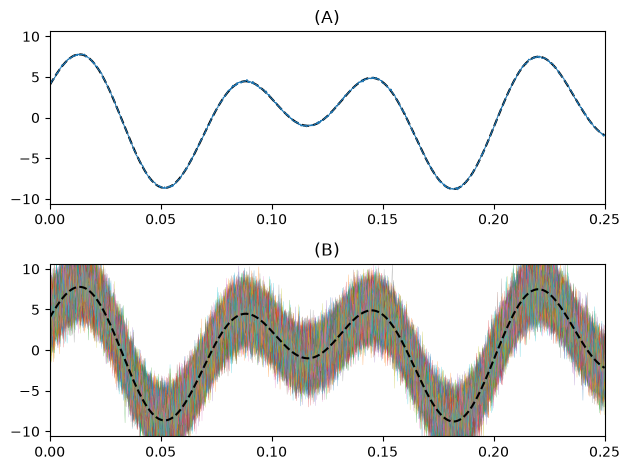

In [8]:
plt.figure(dpi=100)
plt.subplot(2,1,1)
plt.plot(t,x, linestyle="--", color="black")
plt.plot(t,xn.mean(axis=0), linewidth=0.75)
plt.xlim(0,0.25)
plt.ylim(-(a1+a2+a_noise), (a1+a2+a_noise))
plt.title("Ideal signal and mean of sampled signals")
plt.title("(A)")

plt.subplot(2,1,2)
for i_n in range(num_samples):
    plt.plot(t,xn[i_n, :], linewidth=0.15)
plt.plot(t,x, linestyle="--", color="black")
plt.xlim(0,0.25)
plt.ylim(-(a1+a2+a_noise), (a1+a2+a_noise))
plt.title("Ideal signal and each sampled signal")
plt.title("(B)")

plt.tight_layout()
plt.show()

# Calculo de Transformada de Fourier

In [9]:
# Compute the Fourier transform of x
f = fft(x)
# Compute the Fourier transform for each of the sampled signals
fn = fft(xn, axis=-1)
# Compute the Fourier transform for the averaged signal from the sampling process
fm = fft(xn.mean(axis=0))


### Grafico de transformada

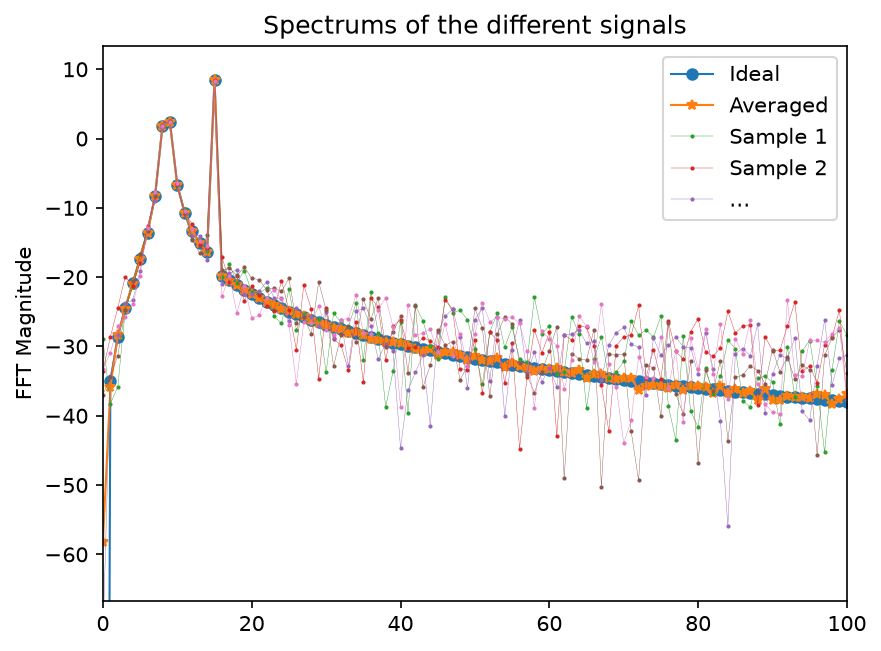

In [10]:

plt.figure(dpi=150)
plot_f(f, marker="-o")
plot_f(fm, marker="-*")
for i in range(5):
    plot_f(fn[i,:], marker="-o", linewidth=0.2, markersize=1.0)
plt.ylabel('FFT Magnitude')
plt.legend(["Ideal", "Averaged", "Sample 1", "Sample 2", "..."])
plt.xlim(0,100)
plt.title("Spectrums of the different signals")
plt.show()

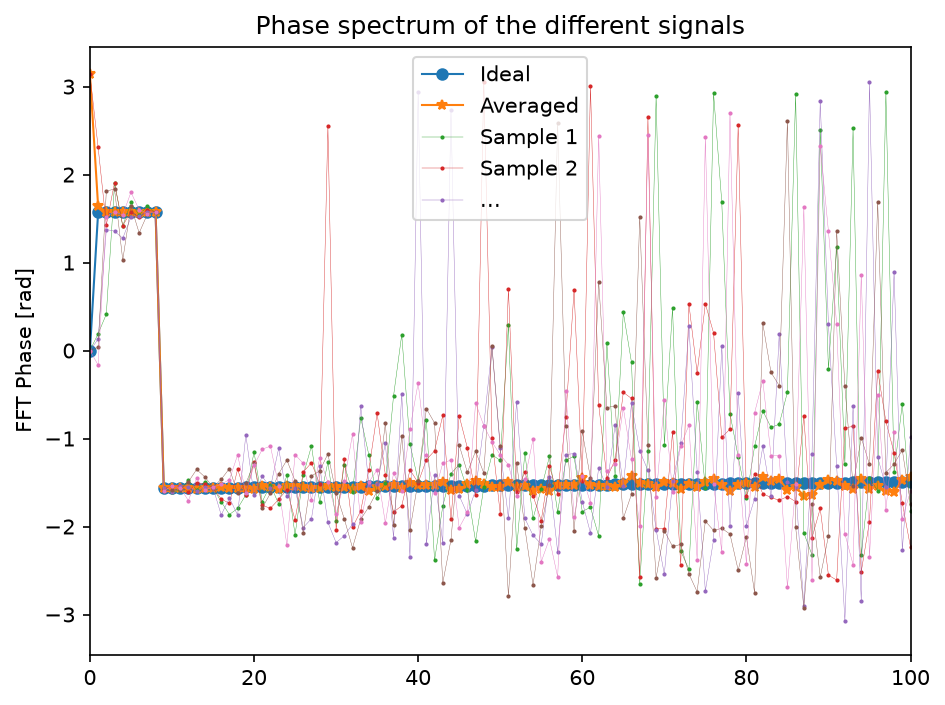

In [11]:

fig = plt.figure(dpi=150)

ax1 = plt.gca()

plot_p(f, marker="-o", ax=ax1, clear_prop=0.0)
plot_p(fm, marker="-*", ax=ax1, clear_prop=0.0)
for i in range(5):
    plot_p(fn[i,:], marker="-o", linewidth=0.2, markersize=1.0, ax=ax1, clear_prop=0.0)
ax1.set_ylabel('FFT Phase [rad]')

plt.legend(["Ideal", "Averaged", "Sample 1", "Sample 2", "..."])

plt.title("Phase spectrum of the different signals")

plt.xlim(0,100)
fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()




### Casteo a clase Metas (calculo automático de incertidumbre)

In [12]:
# Create a list of all the samples with their corresponding uncertainty
metas_array_u = list()
for idx in range(xn.shape[-1]):
    metas_array_u.append(metas.ufloat(xn[:,idx].mean(), xn[:,idx].std(ddof=1)))

# Compute the FFT using the metas-uclib package
metas_fft = metas.unumlib.fft(metas_array_u)

# Calculo de Incertidumbres

## Componentes Complejos

<>:17: SyntaxWarning: invalid escape sequence '\R'
<>:18: SyntaxWarning: invalid escape sequence '\I'
<>:17: SyntaxWarning: invalid escape sequence '\R'
<>:18: SyntaxWarning: invalid escape sequence '\I'
/tmp/ipykernel_15971/1149347218.py:17: SyntaxWarning: invalid escape sequence '\R'
  plt.xlabel("$\Re(X_k)$")
/tmp/ipykernel_15971/1149347218.py:18: SyntaxWarning: invalid escape sequence '\I'
  plt.ylabel("$\Im(X_k)$")


Fourier Coefficients close-up on component 4081


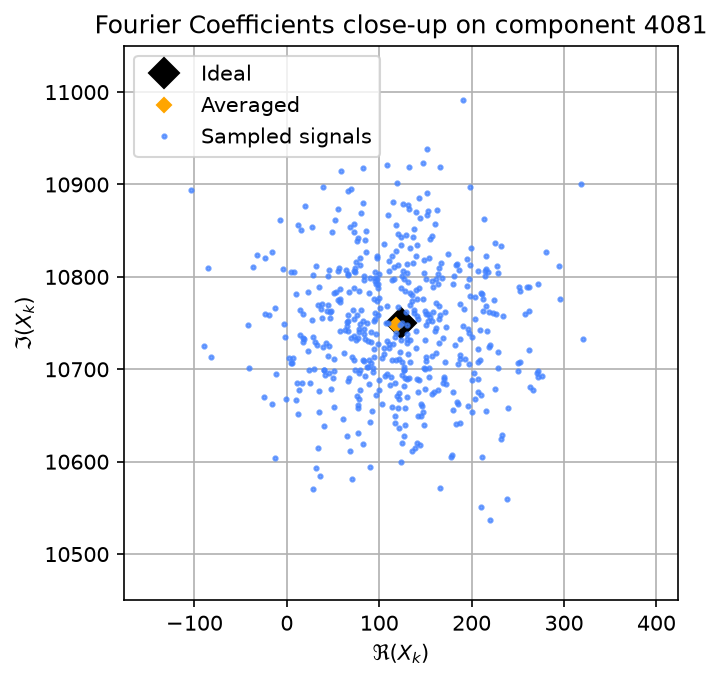

In [13]:
# Select a component to center on
sample_use = 4081

# Plot the Fourier coefficient of the first 1000 arrays.
num_plot = min(num_samples, 1000)
fnf = fn[:num_plot].ravel()
clr = "#4080FF"

plt.figure(dpi=150)
plt.plot(f.real, f.imag, 'kD', ms=10)
plt.plot(fm.real, fm.imag, 'D', ms=5, color="orange")
plt.plot(fnf.real, fnf.imag, 'o', color=clr, mec=clr, ms=2, alpha=0.7)
plt.grid(True)

plt.title(f"Fourier Coefficients close-up on component {sample_use}")
print(f"Fourier Coefficients close-up on component {sample_use}")
plt.xlabel("$\Re(X_k)$")
plt.ylabel("$\Im(X_k)$")
#plt.axis('equal')

plt.xlim(f.real[sample_use]-300,f.real[sample_use]+300)
plt.ylim(f.imag[sample_use]-300,f.imag[sample_use]+300)

plt.legend(["Ideal", "Averaged", "Sampled signals"])

ax = plt.gca()
ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')

plt.show()

<>:14: SyntaxWarning: invalid escape sequence '\R'
<>:15: SyntaxWarning: invalid escape sequence '\I'
<>:14: SyntaxWarning: invalid escape sequence '\R'
<>:15: SyntaxWarning: invalid escape sequence '\I'
/tmp/ipykernel_15971/1879441519.py:14: SyntaxWarning: invalid escape sequence '\R'
  plt.xlabel("$\Re(X_k)$")
/tmp/ipykernel_15971/1879441519.py:15: SyntaxWarning: invalid escape sequence '\I'
  plt.ylabel("$\Im(X_k)$")


Calculated uncertaity on component 4081


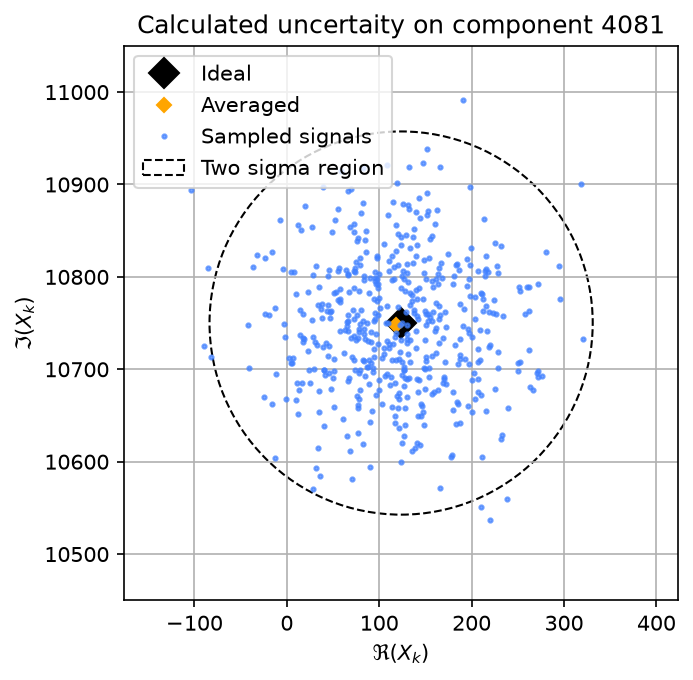

In [14]:

# Plot the Fourier coefficient of the first 1000 arrays.
num_plot = min(num_samples, 1000)
fnf = fn[:num_plot].ravel()
clr = "#4080FF"

plt.figure(dpi=150)
plt.plot(f.real, f.imag, 'kD', ms=10)
plt.plot(fm.real, fm.imag, 'D', ms=5, color="orange")
plt.plot(fnf.real, fnf.imag, 'o', color=clr, mec=clr, ms=2, alpha=0.7)
plt.grid(True)

plt.title(f"Calculated uncertaity on component {sample_use}")
print(f"Calculated uncertaity on component {sample_use}")
plt.xlabel("$\Re(X_k)$")
plt.ylabel("$\Im(X_k)$")
#plt.axis('equal')

plt.xlim(f.real[sample_use]-300,f.real[sample_use]+300)
plt.ylim(f.imag[sample_use]-300,f.imag[sample_use]+300)

range_std=np.sqrt(((a_noise**2)*n))*2
ellipse = Ellipse((f.real[sample_use], f.imag[sample_use]), 
                  range_std*2, 
                  range_std*2, 
                  edgecolor='black', 
                  facecolor='none', 
                  linestyle="--")
ax = plt.gca()
ax.add_patch(ellipse)

plt.legend(["Ideal", "Averaged", "Sampled signals", "Two sigma region"])
ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')

plt.show()






## Magnitud

### Simulación Numerica

In [15]:
# Just get the standard deviation along the sampled axis
sampled_u_abs_fft = np.abs(fn).std(ddof=1,axis=0)

### Metas

In [16]:

# Compute the absolute value of the uncertainties
#metas_u_abs_fft = [metas.umath.abs(a.stdunc).value for a in metas_fft]
metas_u_abs_fft = [metas.umath.abs(a).stdunc for a in metas_fft]


### Método aproximado

In [17]:
# Using the proposed model
variances_abs = np.zeros((fn.shape[1]))
for sample in range(fn.shape[1]):
    variances_abs[sample] = get_comp_abs_var(fn[:,sample].mean(), a_noise, n)
custom_u_abs_fft = np.sqrt(variances_abs)

### Rice

In [18]:


# Using rice
variances_abs_rice = np.zeros_like(variances_abs)
for sample in range(f.shape[0]):
    R = np.sqrt(f[sample].real**2 + f[sample].imag**2)

    # Get the variance of each coeficient
    coef_varinace = ((a_noise**2)*n)
    # Get variance of real and imaginary part
    real_imag_var = coef_varinace/2
    s = np.sqrt(real_imag_var)

    variances_abs_rice[sample] = get_variance_rice(R, s)

rice_u_abs_fft = np.sqrt(variances_abs_rice)

### Plots

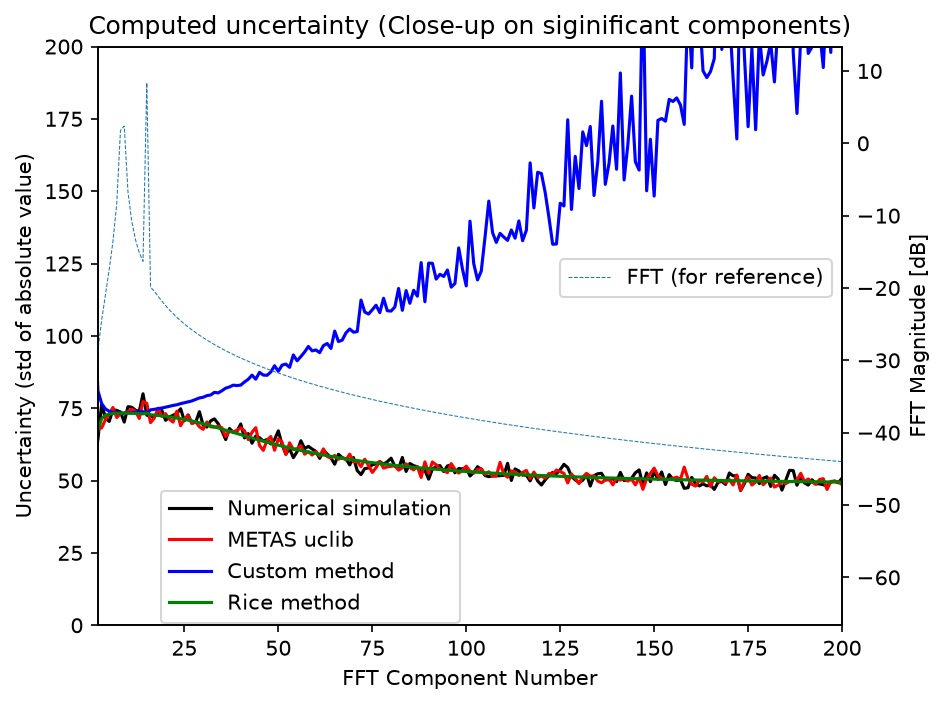

In [19]:
fig, ax1 = plt.subplots(dpi=150)


plt.plot(sampled_u_abs_fft, "black")
plt.plot(metas_u_abs_fft, "red")
plt.plot(custom_u_abs_fft, "blue")
plt.plot(rice_u_abs_fft, "green")


plt.ylim(0,200)
plt.xlim(2,200)

plt.title("Computed uncertainty (Close-up on siginificant components)")
plt.legend(["Numerical simulation", 
            "METAS uclib",
            "Custom method",
            "Rice method"], bbox_to_anchor=(0.5, 0.25))
plt.xlabel("FFT Component Number")
plt.ylabel("Uncertainty (std of absolute value)")

# Add FFT for reference
ax2 = ax1.twinx()  
plot_f(f, marker="--", ax=ax2, linewidth=0.5)
ax2.set_ylabel('FFT Magnitude [dB]')
plt.legend(["FFT (for reference)"], bbox_to_anchor=(1., 0.65))

fig.tight_layout()  # otherwise the right y-label is slightly clipped


plt.show()



## Fase

### Simulación numérica

In [20]:
# Just get the standard deviation along the sampled axis
sampled_u_phase_fft = np.arctan2(fn.imag,fn.real).std(ddof=1,axis=0)

### Metas

In [21]:
# Compute the absolute value of the uncertainties
metas_u_phase_fft = [metas.umath.atan(a.imag.stdunc/a.real.stdunc).value for a in metas_fft]

### Aproximación (Serie de Taylor)

In [22]:
variances_phase = np.zeros((fn.shape[1]))
for sample in range(fn.shape[1]):


    variances_phase[sample] = get_comp_phase_var(fn[:,sample].mean(), a_noise, n)

custom_u_phase_fft = np.sqrt(variances_phase)

### Plots

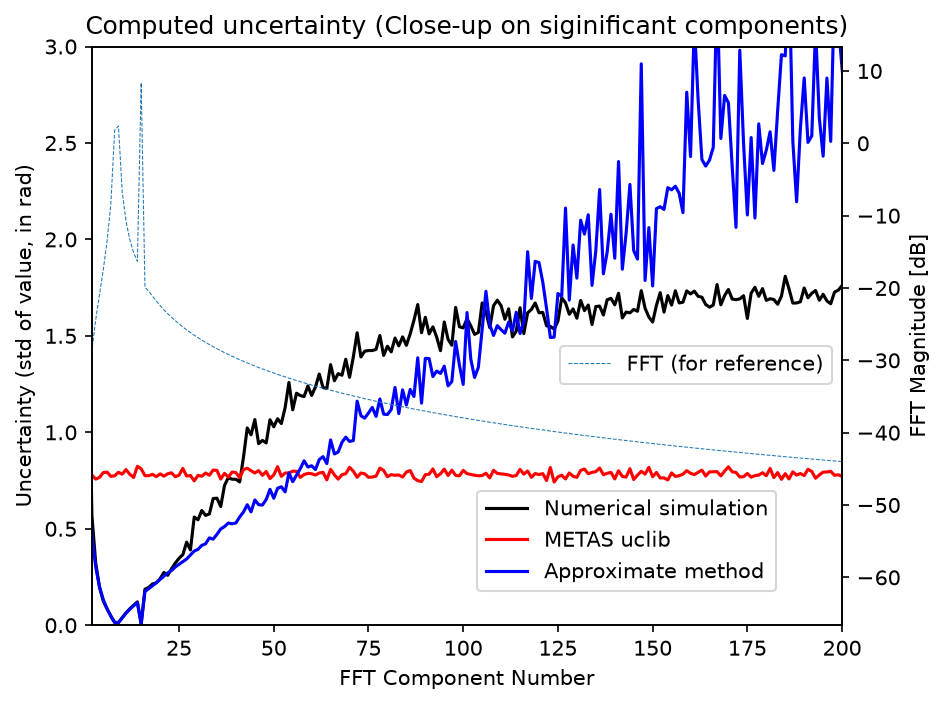

In [23]:
fig, ax1 = plt.subplots(dpi=150)


plt.plot(sampled_u_phase_fft, "black")
plt.plot(metas_u_phase_fft, "red")
plt.plot(custom_u_phase_fft, "blue")


plt.ylim(0,3)
plt.xlim(2,200)

plt.title("Computed uncertainty (Close-up on siginificant components)")
plt.legend(["Numerical simulation", 
            "METAS uclib",
            "Approximate method",
            ], bbox_to_anchor=(0.5, 0.25))
plt.xlabel("FFT Component Number")
plt.ylabel("Uncertainty (std of value, in rad)")

# Add FFT for reference
ax2 = ax1.twinx()  
plot_f(f, marker="--", ax=ax2, linewidth=0.5)
# plot_p(fm, marker="-*", ax=ax2, clear_prop=0.0, linewidth=0.5)
ax2.set_ylabel('FFT Magnitude [dB]')
plt.legend(["FFT (for reference)"], bbox_to_anchor=(1., 0.5))

fig.tight_layout()  # otherwise the right y-label is slightly clipped


plt.show()

